In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 100,                   # high resolution

    # Axes
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']


In [11]:

base_path = "../AXA_peptides/"
cutoff = 0.5

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open = []
avg_rho = []
err_pop_open = []
err_avg_rho = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath = os.path.join(base_path, aa, "SIM", "rho_front_noexcl", "rho_front_frames.npy")


    rho_front = np.load(filepath) # left, right
    S = rho_front[:,1]
        
    avg = np.mean(S)
    fopen = np.mean((S<cutoff)*1, axis=0)

    pop_open.append(fopen)
    avg_rho.append(avg)

    if fopen ==1.0:
        err_pop_open.append(0.0)
        err_avg_rho.append(0.0)
        continue

    # errors    
    reblock_data = pyblock.blocking.reblock((S>cutoff)*1)
    opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
    err_fopen = reblock_data[opt][4]
    reblock_data = pyblock.blocking.reblock(S)
    opt = pyblock.blocking.find_optimal_block(len(S), reblock_data)[0]
    err_avg = reblock_data[opt][4]
    err_pop_open.append(err_fopen)
    err_avg_rho.append(err_avg)
       

df['fopen'] = np.round(pop_open, 4)
df['fopen ±'] = np.round(err_pop_open, 4)
df['SASA'] = np.round(avg_rho, 2)
df['SASA ±'] = np.round(err_avg_rho, 2)
df['aa'] = code

# save
df.to_csv(f'AXA_tripeptides_rho_front_neigh_cutoff_{cutoff}.csv', index=False)








In [12]:
np.mean(df['fopen'])

0.9761263157894736

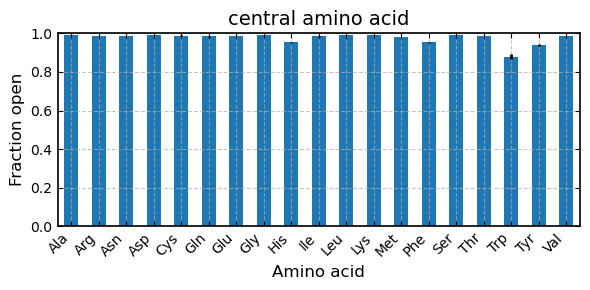

In [13]:

df.plot(x='AA', y='fopen', yerr='fopen ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('Fraction open')
plt.xticks(rotation=45, ha='right')  
plt.title('central amino acid')
plt.ylim(0,1)
plt.tight_layout()
plt.savefig('fraction_open_aa_rho_front_neigh.png')

In [56]:
df

,AA,fopen,fopen ±,SASA,SASA ±,aa
0,Ala,0.9562,0.0029,0.05,0.00,A
1,Arg,0.9454,0.0035,0.06,0.00,R
2,Asn,0.9278,0.0039,0.08,0.00,N
3,Asp,0.9240,0.0047,0.09,0.01,D
4,Cys,0.9252,0.0039,0.08,0.00,C
5,Gln,0.9415,0.0036,0.07,0.00,Q
6,Glu,0.9441,0.0035,0.07,0.00,E
7,Gly,0.9198,0.0033,0.09,0.00,G
8,His,0.8639,0.0078,0.14,0.01,H
9,Ile,0.9205,0.0042,0.09,0.00,I


In [25]:
np.min(sasa)

0.0

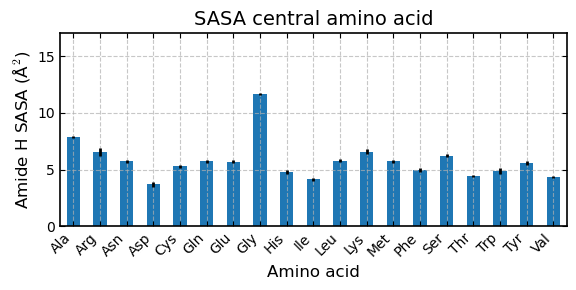

In [4]:

df.plot(x='AA', y='SASA', yerr='SASA ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('Amide H SASA (Å$^2$)')
plt.xticks(rotation=45, ha='right')    
plt.title('SASA central amino acid')
plt.ylim(0,17)
plt.tight_layout()
plt.savefig('SASA_aa.png')

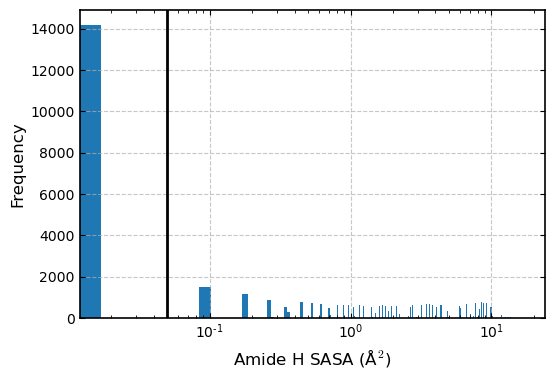

In [67]:
sasa = np.load('../AXA_peptides/Trp/SIM/SASA/amideH_SASA_traj_fit.npy')[:,1]

plt.hist(sasa, bins=1000)
plt.axvline(0.05, color='black')
plt.xlabel('Amide H SASA (Å$^2$)')
plt.ylabel('Frequency')
plt.xscale('log')

In [68]:
sasa[np.where(sasa<0.2)[0]]

array([8.8887326e-02, 6.2648236e-04, 5.5436288e-07, ..., 3.9150799e-04,
       3.4643836e-07, 9.1072142e-02], dtype=float32)

/tmp/ipykernel_490471/269309528.py:4: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  plt.ylim(0,1e0)


(0.03736859540328541, 1.0)

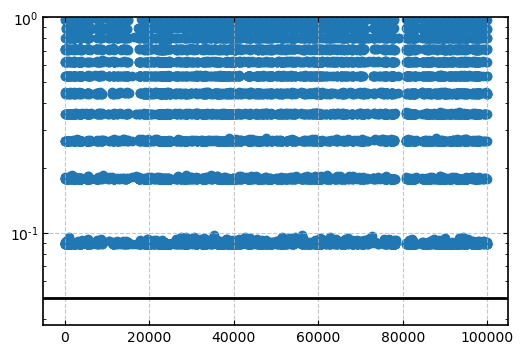

In [69]:
plt.scatter(np.arange(len(sasa)), sasa)
plt.yscale('log')
plt.axhline(0.05, color='black')
plt.ylim(0,1e0)

In [70]:
for cut in [0.01, 0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.5, 1.0]:
    print(f"Cutoff: {cut}, Fraction open: {np.mean((sasa>cut)*1):.4f}")



Cutoff: 0.01, Fraction open: 0.8581
Cutoff: 0.02, Fraction open: 0.8580
Cutoff: 0.05, Fraction open: 0.8580
Cutoff: 0.075, Fraction open: 0.8580
Cutoff: 0.1, Fraction open: 0.8432
Cutoff: 0.15, Fraction open: 0.8432
Cutoff: 0.2, Fraction open: 0.8317
Cutoff: 0.5, Fraction open: 0.8063
Cutoff: 1.0, Fraction open: 0.7668


(0.0, 1.0)

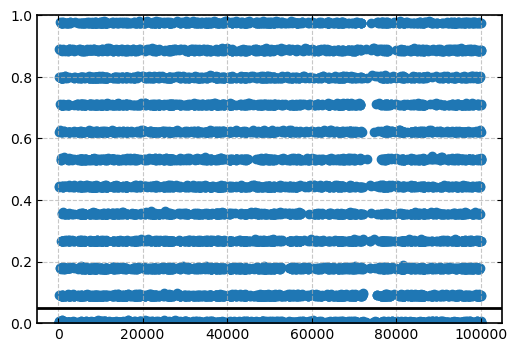

In [59]:
plt.scatter(np.arange(len(sasa)), sasa)
plt.axhline(0.05, color='black')
plt.ylim(0,1)

In [77]:
SASA = np.load('../../MD_DATA/Ubiquitin/SASA/amideH_SASA_traj10.npy')
res = np.loadtxt('../../MD_DATA/Ubiquitin/SASA/amideresidues.txt')
SASA.shape

(20001, 73)

In [92]:
RES = 36
idx = np.where(res==RES)[0][0]

for cut in [0.01, 0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.5, 1.0, 4.0]:
    print(f"Cutoff: {cut}, Fraction open: {np.mean((SASA[:,idx]>cut)*1):.4f}")



Cutoff: 0.01, Fraction open: 0.0114
Cutoff: 0.02, Fraction open: 0.0114
Cutoff: 0.05, Fraction open: 0.0114
Cutoff: 0.075, Fraction open: 0.0114
Cutoff: 0.1, Fraction open: 0.0073
Cutoff: 0.15, Fraction open: 0.0073
Cutoff: 0.2, Fraction open: 0.0051
Cutoff: 0.5, Fraction open: 0.0023
Cutoff: 1.0, Fraction open: 0.0007
Cutoff: 4.0, Fraction open: 0.0000


In [94]:


for cut in [0.01, 0.02, 0.05, 0.075, 0.1, 0.15, 0.2, 0.5, 1.0, 4.0]:
    print(f"Cutoff: {cut}, Fraction open: {np.mean((SASA.flatten()>cut)*1):.4f}")



Cutoff: 0.01, Fraction open: 0.3298
Cutoff: 0.02, Fraction open: 0.3293
Cutoff: 0.05, Fraction open: 0.3293
Cutoff: 0.075, Fraction open: 0.3293
Cutoff: 0.1, Fraction open: 0.3173
Cutoff: 0.15, Fraction open: 0.3172
Cutoff: 0.2, Fraction open: 0.3087
Cutoff: 0.5, Fraction open: 0.2895
Cutoff: 1.0, Fraction open: 0.2608
Cutoff: 4.0, Fraction open: 0.1620


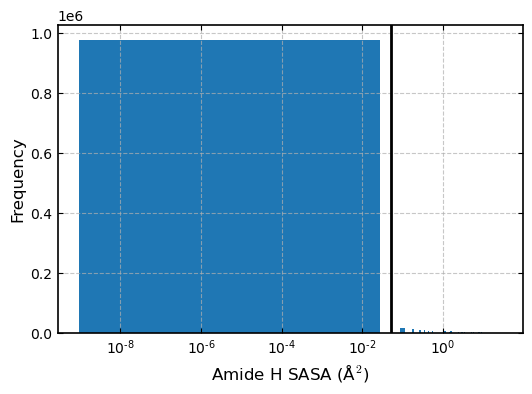

In [93]:


plt.hist(SASA.flatten(), bins=1000)
plt.axvline(0.05, color='black')
plt.xlabel('Amide H SASA (Å$^2$)')
plt.ylabel('Frequency')
plt.xscale('log')